# PROCESS

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('metadata.csv', usecols = ['journal', 'doi', 'pdf_json_files'],
                dtype = {'pdf_json_files' : str,
                         'doi': str,
                          'journal' : str})

# We have totally 199944 files alone in the dataframe, BUT less than 199944 in the document folder (see code 5) 
df.head()

,doi,journal,pdf_json_files
0,10.1186/1471-2334-1-6,BMC Infect Dis,document_parses/pdf_json/d1aafb70c066a2068b027...
1,10.1186/rr14,Respir Res,document_parses/pdf_json/6b0567729c2143a66d737...
2,10.1186/rr19,Respir Res,document_parses/pdf_json/06ced00a5fc04215949aa...
3,10.1186/rr44,Respir Res,document_parses/pdf_json/348055649b6b8cf2b9a37...
4,10.1186/rr61,Respir Res,document_parses/pdf_json/5f48792a5fa08bed9f560...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 599616 entries, 0 to 599615
Data columns (total 3 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   doi             321299 non-null  object
 1   journal         560554 non-null  object
 2   pdf_json_files  199944 non-null  object
dtypes: object(3)
memory usage: 13.7+ MB


In [4]:
import os
os.getcwd()

'C:\\Users\\LocalAdmin\\Downloads\\Covid-19 Article Clustering Data'

In [5]:
df.iloc[0]['pdf_json_files']  # Name of the json file which has all contents of the particular research paper

'document_parses/pdf_json/d1aafb70c066a2068b02786f8929fd9c900897fb.json'

In [6]:
# Directory where all research articles are present (in json format)
json_files_path = r'C:\Users\LocalAdmin\Downloads\Covid-19 Article Clustering Data\document_parses\pdf_json'

In [7]:
len(os.listdir(json_files_path)) # There were actually more than 100 Million data files but we took only 141445 files

141445

In [8]:
import random
import os
random.seed(42)
# Lets sample 10000 files from the files directory (Hard to process all 141445)
NO_OF_SAMPLES = 10000
samples = random.sample(os.listdir(json_files_path), NO_OF_SAMPLES)

In [9]:
samples[:5]

['234abf43ec014de9616407bcd48f671360195905.json',
 '07da062617f1f8841c4b7b87bbca7cbb14b05d01.json',
 '56df3c03a94c4a16a2b03c6a9d4f7c9dac4bbf4b.json',
 '4d54f710a365c24cc897968fca43d3672b9acecf.json',
 '46804ad94d5dd5931dd3c2d4af0c9a8817b08a12.json']

In [10]:
df['pdf_json_files'][:5][0]

'document_parses/pdf_json/d1aafb70c066a2068b02786f8929fd9c900897fb.json'

In [11]:
samples = ['document_parses/pdf_json/' + filename for filename in samples] # To maintain consitency with df['pdf_json_files']

In [12]:
import json

In [13]:
# Check whether each of our samples (10000 files) are in our dataframe df['pdf_json_files'] too
newFilesInBoth = []
listOfAllFiles = df['pdf_json_files'].tolist()
for sample_file in samples:
    if sample_file in listOfAllFiles:
        newFilesInBoth.append(sample_file)

In [14]:
newFilesInBoth

['document_parses/pdf_json/234abf43ec014de9616407bcd48f671360195905.json',
 'document_parses/pdf_json/07da062617f1f8841c4b7b87bbca7cbb14b05d01.json',
 'document_parses/pdf_json/56df3c03a94c4a16a2b03c6a9d4f7c9dac4bbf4b.json',
 'document_parses/pdf_json/4d54f710a365c24cc897968fca43d3672b9acecf.json',
 'document_parses/pdf_json/46804ad94d5dd5931dd3c2d4af0c9a8817b08a12.json',
 'document_parses/pdf_json/2c330b4c254d32992d519c63bbc2aba0e522a47e.json',
 'document_parses/pdf_json/207ff55c2ed71d6032eac31e5186aa73ec4e4da0.json',
 'document_parses/pdf_json/1b817fd8189755f2b5c72cb80e7b76af937f8eae.json',
 'document_parses/pdf_json/8551ef9f21427e6645dd640ff40e96d52a0b756f.json',
 'document_parses/pdf_json/0a23247c10fffc2f925c2ddee2451c552286d89b.json',
 'document_parses/pdf_json/098020bf46261794ddfde58626507fe362e16205.json',
 'document_parses/pdf_json/1db4560940a913194230a37755d10fa154b09d15.json',
 'document_parses/pdf_json/4501f6a5db2ec431936c04e04d1ec72f97603596.json',
 'document_parses/pdf_jso

In [15]:
len(newFilesInBoth) # So, out of 1000 samples we took, only 8847 files were present in the dataframe

8847

In [16]:
def parse_json_files(file_name):             # Parse each file
    with open('./' + file_name) as j_file:
        
        fileContent = json.load(j_file)
        
        # Extract paper_id, title, authors, abstract, body, journalName and doi from each paper
        
        paper_id = fileContent['paper_id']   # Each paper has an unique paper_id
        metadata = fileContent['metadata']   # Meta data talks a lot more
        
        title    = metadata['title']         # Title of the paper (unique to every paper)

        authors  = []
        
        for eachAuthor in metadata['authors']:
            firstName = '' if eachAuthor['first'] == [] else eachAuthor['first']
            middleName = '' if eachAuthor['middle'] == [] else eachAuthor['middle']
            lastName = '' if eachAuthor['last'] == [] else eachAuthor['last']
            try:
                authorName = firstName + ' ' + middleName + ' ' + lastName
            except:
                authorName = ''
            authors.append(authorName)
            
        abstract  = []
        body_text = [] 
        
        for each_para in fileContent['abstract']:
            abstract.append(each_para['text'])
        abstract = '/n'.join(abstract)               # Join all paras by new line
        
        for each_body in fileContent['body_text']:
            body_text.append(each_body['text'])      # Join all paras by new line
        body_text = '/n'.join(body_text)
        
        journalName = df['journal'][df['pdf_json_files'] == file_name] # file name starting with document_parses/pdf_json/
        doi         = df['doi'][df['pdf_json_files'] == file_name]

        return abstract , body_text, title, paper_id, authors, journalName, doi

In [17]:
articles_df = pd.DataFrame()
articles_df['newFilesInBoth'] = newFilesInBoth

In [19]:
newCols = ['Abstract', 'Body', 'Title' 'ID', 'Authors', 'Journal', 'DOI']
#articles_df = pd.concat([articles_df, pd.DataFrame(columns = newCols)], axis=1)
abstracts, body_texts, titles, paper_ids, authors_, journalNames, dois = [],[],[],[],[],[],[]
necessData = []
for index, file in enumerate(articles_df['newFilesInBoth']):
    abstract, body_text, title, paper_id, authors, journalName, doi = parse_json_files(file)
    abstracts.append(abstract)
    body_texts.append(body_text)
    titles.append(title)
    paper_ids.append(paper_id)
    authors_.append(authors)
    journalNames.append(journalName)
    dois.append(doi)
    
articles_df['Abstract'] = abstracts
articles_df['Body']     = body_texts
articles_df['Title']    = titles
articles_df['ID']    = paper_ids
articles_df['Authors'] = authors_
articles_df['Journal'] = journalNames
articles_df['DOI'] = dois

In [20]:
articles_df.head()

,newFilesInBoth,Abstract,Body,Title,ID,Authors,Journal,DOI
0,document_parses/pdf_json/234abf43ec014de961640...,N-Variant Execution (NVX) systems utilize arti...,Memory errors are a continuous source of softw...,Distributed Heterogeneous N-Variant Execution,234abf43ec014de9616407bcd48f671360195905,"[Alexios Voulimeneas, Dokyung Song, Fabian ...","32355 Detection of Intrusions and Malware, ...",32355 10.1007/978-3-030-52683-2_11 Name: do...
1,document_parses/pdf_json/07da062617f1f8841c4b7...,The construction of discourse blaming EU migra...,Eurosceptic inflection often added by London-b...,Britain First: A Journey into Emotive Rhetoric,07da062617f1f8841c4b7b87bbca7cbb14b05d01,[],"45791 Post-Truth, Post-Press, Post-Europe N...",45791 10.1007/978-3-030-55571-9_7 Name: doi...
2,document_parses/pdf_json/56df3c03a94c4a16a2b03...,Adolescents and youth living with HIV have poo...,"Adolescents and youth, 10 to 24 years of age, ...",Interventions to Improve Antiretroviral Therap...,56df3c03a94c4a16a2b03c6a9d4f7c9dac4bbf4b,"[, , Stephen Arpadi, Batya Elul, , , Louise ...","11353 AIDS Behav Name: journal, dtype: object","11353 10.1007/s10461-020-02822-4 Name: doi,..."
3,document_parses/pdf_json/4d54f710a365c24cc8979...,,Housing is an essential component of human lif...,International Journal of Environmental Researc...,4d54f710a365c24cc897968fca43d3672b9acecf,"[Jisun Kim, Seunghyun Yoo, Lorenzo Capasso, ]",457545 Int J Environ Res Public Health Name...,"457545 10.3390/ijerph18031067 Name: doi, dt..."
4,document_parses/pdf_json/46804ad94d5dd5931dd3c...,,The pandemic acute respiratory syndrome corona...,How urinary stone emergencies changed in the t...,46804ad94d5dd5931dd3c2d4af0c9a8817b08a12,"[Simone Flammia, Stefano Salciccia, Antonio ...","510128 Urolithiasis Name: journal, dtype: o...",510128 10.1007/s00240-020-01198-3 Name: doi...


In [21]:
articles_df.to_csv('Part1_Data_Preprocessing.csv', index=False)

In [22]:
articles_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8847 entries, 0 to 8846
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   newFilesInBoth  8847 non-null   object
 1   Abstract        8847 non-null   object
 2   Body            8847 non-null   object
 3   Title           8847 non-null   object
 4   ID              8847 non-null   object
 5   Authors         8847 non-null   object
 6   Journal         8847 non-null   object
 7   DOI             8847 non-null   object
dtypes: object(8)
memory usage: 553.1+ KB


In [23]:
# Fill in Empty rows
articles_df.loc[articles_df['Abstract']=='', 'Abstract'] = 'Not Provided'
articles_df.loc[articles_df['Authors'].apply(len)==0, 'Authors'] = 'Not Provided' # Getting len of each element of a string column

In [24]:
articles_df.head()

,newFilesInBoth,Abstract,Body,Title,ID,Authors,Journal,DOI
0,document_parses/pdf_json/234abf43ec014de961640...,N-Variant Execution (NVX) systems utilize arti...,Memory errors are a continuous source of softw...,Distributed Heterogeneous N-Variant Execution,234abf43ec014de9616407bcd48f671360195905,"[Alexios Voulimeneas, Dokyung Song, Fabian ...","32355 Detection of Intrusions and Malware, ...",32355 10.1007/978-3-030-52683-2_11 Name: do...
1,document_parses/pdf_json/07da062617f1f8841c4b7...,The construction of discourse blaming EU migra...,Eurosceptic inflection often added by London-b...,Britain First: A Journey into Emotive Rhetoric,07da062617f1f8841c4b7b87bbca7cbb14b05d01,Not Provided,"45791 Post-Truth, Post-Press, Post-Europe N...",45791 10.1007/978-3-030-55571-9_7 Name: doi...
2,document_parses/pdf_json/56df3c03a94c4a16a2b03...,Adolescents and youth living with HIV have poo...,"Adolescents and youth, 10 to 24 years of age, ...",Interventions to Improve Antiretroviral Therap...,56df3c03a94c4a16a2b03c6a9d4f7c9dac4bbf4b,"[, , Stephen Arpadi, Batya Elul, , , Louise ...","11353 AIDS Behav Name: journal, dtype: object","11353 10.1007/s10461-020-02822-4 Name: doi,..."
3,document_parses/pdf_json/4d54f710a365c24cc8979...,Not Provided,Housing is an essential component of human lif...,International Journal of Environmental Researc...,4d54f710a365c24cc897968fca43d3672b9acecf,"[Jisun Kim, Seunghyun Yoo, Lorenzo Capasso, ]",457545 Int J Environ Res Public Health Name...,"457545 10.3390/ijerph18031067 Name: doi, dt..."
4,document_parses/pdf_json/46804ad94d5dd5931dd3c...,Not Provided,The pandemic acute respiratory syndrome corona...,How urinary stone emergencies changed in the t...,46804ad94d5dd5931dd3c2d4af0c9a8817b08a12,"[Simone Flammia, Stefano Salciccia, Antonio ...","510128 Urolithiasis Name: journal, dtype: o...",510128 10.1007/s00240-020-01198-3 Name: doi...


In [25]:
articles_df.dropna(inplace=True)

In [26]:
from tqdm import tqdm
from langdetect import detect
from langdetect import DetectorFactory

# Set seed
DetectorFactory.seed = 0

txtLanguages = []
for index, text in enumerate(articles_df['Body']):
    # We can directly do print(detect(text))
    # But we assume the instead of detecting through the entire body, we can do that with 1st 50 words
    allWordsInText = text.split(' ')
    
    if len(allWordsInText) > 50:
        text = ' '.join(allWordsInText[:50])
    else:
        text = ' '.join(allWordsInText)
        
    try:
        txtLang = detect(text)
    except:
        txtLang = 'Not Detected'
    txtLanguages.append(txtLang)

In [27]:
articles_df['LanguageOfText'] = txtLanguages

In [28]:
txtLanguages.count('en')

8541

In [29]:
# Let us create a dictionary for all languages from the list
langCountsDict = {}
for lang in set(txtLanguages):
    langCountsDict[lang] = txtLanguages.count(lang)

In [30]:
langCountsDict

{'zh-cn': 2,
 'pt': 5,
 'it': 2,
 'ca': 3,
 'nl': 12,
 'Not Detected': 2,
 'de': 123,
 'es': 90,
 'en': 8541,
 'sq': 2,
 'cy': 5,
 'fr': 60}

In [31]:
articles_df.loc[articles_df['LanguageOfText']=='Not Detected', 'Body']

3247                                     . . . . . . 507 
5609    •❛❜♦r❛t♦r② ❡①♣❡r✐♠❡♥t t❤❛t s❤♦✇❡❞ t❤❛t ❛t ✸✵❽❛...
Name: Body, dtype: object

In [32]:
list(langCountsDict.values())[0]

2

In [33]:
# Let us plot a distribution of the languages in our text
from bokeh.plotting import figure, show
from bokeh.io import output_notebook
#from bokeh.models import VBar
output_notebook()

myfig = figure(title = 'Counts of languages of texts',
               x_range = list(langCountsDict.keys()),   # Important for Bar Plot in Bokeh
               plot_height = 400,
               plot_width = 400,
               x_axis_label = 'Languages',
               y_axis_label = 'Counts')
myfig.vbar(x = list(langCountsDict.keys()), top = list(langCountsDict.values()), width=0.8)
myfig.xaxis.major_label_orientation = "vertical"
show(myfig)

Loading BokehJS ...

In [34]:
# def get_breaks(content, length):
#     data = ""
#     words = content.split(' ')
#     print(words)
#     total_chars = 0

#     # add break every length characters
#     for i in range(len(words)):
#         total_chars += len(words[i])
#         if total_chars > length:
#             data = data + "<br>" + words[i]
#             total_chars = 0
#         else:
#             data = data + " " + words[i]
#     return data
# get_breaks('Hello guys, my name is Praveen', 5)

In [35]:
# go through each text
#     # split by space into list, take the first x intex, join with space
#     text = df.iloc[ii]['body_text'].split(" ")
    
#     lang = "en"
#     try:
#         if len(text) > 50:
#             lang = detect(" ".join(text[:50]))
#         elif len(text) > 0:
#             lang = detect(" ".join(text[:len(text)]))

#     except Exception as e:
#         all_words = set(text)
#         try:
#             lang = detect(" ".join(all_words))
#         # what!! :( let's see if we can find any text in abstract...
#         except Exception as e:
            
#             try:
#                 # let's try to label it through the abstract then
#                 lang = detect(df.iloc[ii]['abstract_summary'])
#             except Exception as e:
#                 lang = "unknown"
#                 pass
    
#     # get the language    
#     languages.append(lang)

In [36]:
#pip install langdetect

In [37]:
# Drop Non-English texts
articles_df = articles_df.loc[articles_df['LanguageOfText'] == 'en']

In [38]:
articles_df.to_csv('Part2_Data_Preprocessing.csv', index=False)

In [39]:
# Stop Words
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
print(stopwords.words('english'))

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', '

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LocalAdmin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [40]:
stop_words = stopwords.words('english')

custom_stop_words = [
    'doi', 'preprint', 'copyright', 'peer', 'reviewed', 'org', 'https', 'et', 'al', 'author', 'figure', 
    'rights', 'reserved', 'permission', 'used', 'using', 'biorxiv', 'medrxiv', 'license', 'fig', 'fig.', 
    'al.', 'Elsevier', 'PMC', 'CZI'
]

all_stop_words = stop_words + custom_stop_words

In [41]:
import string
punctuations = string.punctuation  # word.isalpha() can also be used to remove punctuation
punctuations

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [42]:
from nltk.tokenize import word_tokenize
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LocalAdmin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [43]:
def clean_text(sentence):
    finalWords = []
    words = word_tokenize(sentence)   # sentence.split(' ')
    for word in words:
        if (word in punctuations) or (word in all_stop_words): # Remove Punct & Stopwords
            continue                                              # word.isalpha() can also be used to remove punctuation
        finalWords.append(word.lower())                           # Make all words lowercase
    return ' '.join(finalWords)
#     words = [word for word in words if word not in punctutations]
#     words = [word for word in words if word not in custom_stop_words]
#     words = [word.lower() for word in words ]

In [44]:
clean_text('Hello, My name is Praveen Kumar. M')

'hello my name praveen kumar m'

In [45]:
articles_df.loc[:, 'cleaned_body_text'] = articles_df['Body'].apply(clean_text)

In [46]:
articles_df.to_csv('Part3_Data_Preprocessing.csv', index=False)

# Vectorization

In [47]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [48]:
def vectorize(text, maxx_features):
    
    vectorizer = TfidfVectorizer(max_features=maxx_features)
    X = vectorizer.fit_transform(text)
    return X

In [49]:
max_features = 2**12
X = vectorize(articles_df['cleaned_body_text'].values, max_features)

# PCA

In [50]:
X

<8541x4096 sparse matrix of type '<class 'numpy.float64'>'
	with 5102359 stored elements in Compressed Sparse Row format>

In [51]:
# We reduce the dimensions while still keeping 95% variance by applying PCA to our vectorized data
# This will reduce the complexity of our dimensionality reduction step and filter noise

from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, random_state=42)
X_reduced= pca.fit_transform(X.toarray())
X_reduced.shape   # 8541 x 4096 transformed to 8541 x 2329 while maintaining 95% variance

(8541, 2329)

In [52]:
# Save this array into csv file
import numpy
numpy.savetxt('X_reduced.csv', 
               X_reduced, 
               delimiter = ',')  # Without index by default

# K-Means

In [53]:
from sklearn.cluster import KMeans
wcss = [] 
k = NUM_OF_CLUSTERS = 30
for i in range(1, k): 
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 42)
    kmeans.fit(X_reduced) 
    wcss.append(kmeans.inertia_)
# “init” argument is the method for initializing the centroid. 
# We calculated the WCSS value for each K value. Now we have to plot the WCSS with K value

NameError: name 'plt' is not defined

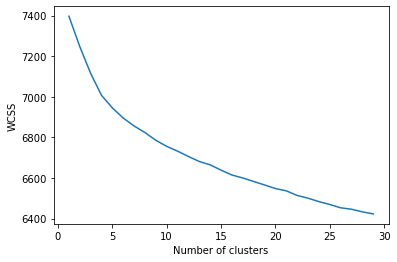

In [55]:
import matplotlib.pyplot as plt
plt.plot(range(1, k), wcss)
plt.xlabel('Number of clusters')
plt.ylabel('WCSS') 
plt.show()

In [56]:
# From this plot, Let us select optimal # of clusters, k to be 9
k = 9
kmeans = KMeans(n_clusters=k, random_state=42)
y_pred = kmeans.fit_predict(X_reduced)

In [58]:
articles_df['clustr_pred'] = y_pred

In [59]:
articles_df.to_csv('Part4_Data_Preprocessing.csv', index=False)

# T_SNE FOR DIMENSIONALITY REDUCTION

In [60]:
# Using t-SNE we can reduce our high dimensional features vector to 2 dimensions. 
# By using the 2 dimensions as x,y coordinates, the body_text can be plotted. 
# t-SNE will attempt to preserve the relations of the higher dimensional data as closely as possible when shrunk to 2D. 
# The similar article will thus be in closer proximity to each other.

from sklearn.manifold import TSNE

tsne = TSNE(verbose=1, perplexity=50)  # Changed perplexity from 100 to 50 per FAQ
X_embedded = tsne.fit_transform(X.toarray())  # See that we are only using the original X and not the X_reduced from PCA

[t-SNE] Computing 151 nearest neighbors...
[t-SNE] Indexed 8541 samples in 0.145s...
[t-SNE] Computed neighbors for 8541 samples in 6.527s...
[t-SNE] Computed conditional probabilities for sample 1000 / 8541
[t-SNE] Computed conditional probabilities for sample 2000 / 8541
[t-SNE] Computed conditional probabilities for sample 3000 / 8541
[t-SNE] Computed conditional probabilities for sample 4000 / 8541
[t-SNE] Computed conditional probabilities for sample 5000 / 8541
[t-SNE] Computed conditional probabilities for sample 6000 / 8541
[t-SNE] Computed conditional probabilities for sample 7000 / 8541
[t-SNE] Computed conditional probabilities for sample 8000 / 8541
[t-SNE] Computed conditional probabilities for sample 8541 / 8541
[t-SNE] Mean sigma: 0.317906
[t-SNE] KL divergence after 250 iterations with early exaggeration: 87.775795
[t-SNE] KL divergence after 1000 iterations: 2.085625


In [64]:
X_embedded # 2 dimensional (high dim data ----> 2 dim)

array([[ 57.898174 , -12.278424 ],
       [ 39.94606  ,   3.5892894],
       [ 67.41543  ,  23.895384 ],
       ...,
       [-23.72065  ,  32.25628  ],
       [-12.786873 ,  26.590546 ],
       [-36.23903  ,  22.639326 ]], dtype=float32)

C:\Users\LocalAdmin\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


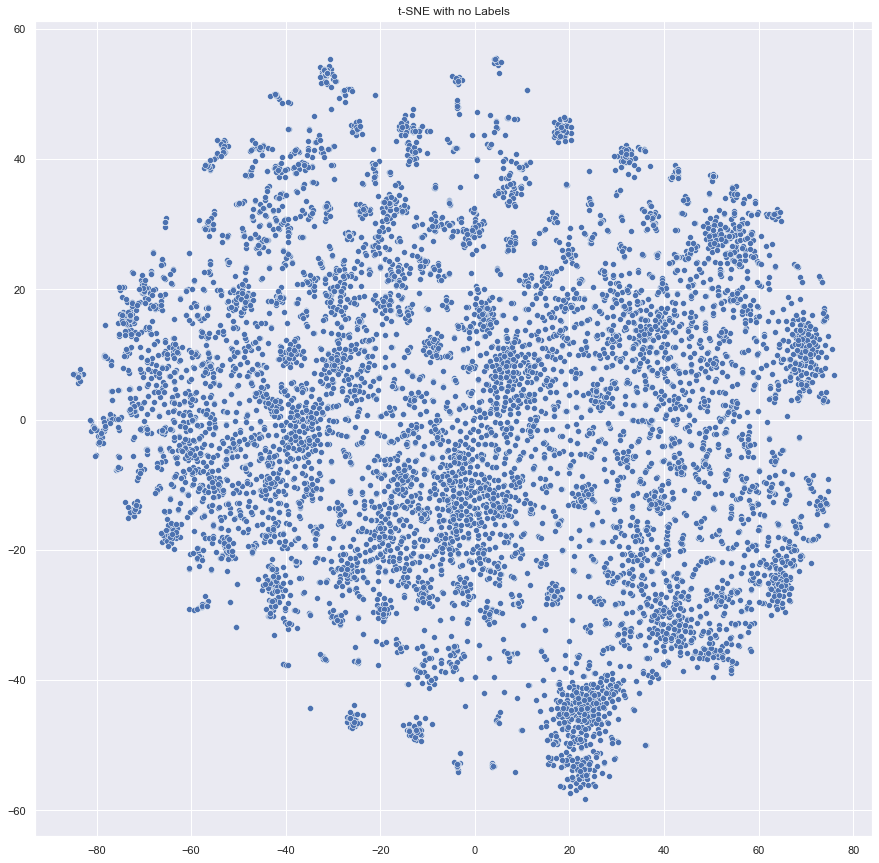

In [61]:
from matplotlib import pyplot as plt
import seaborn as sns

# sns settings
sns.set(rc={'figure.figsize':(15,15)})

# colors
palette = sns.color_palette("bright", 1)

# plot
sns.scatterplot(X_embedded[:,0], X_embedded[:,1], palette=palette)
plt.title('t-SNE with no Labels')
plt.savefig("t-sne_covid19.png")
plt.show()

C:\Users\LocalAdmin\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


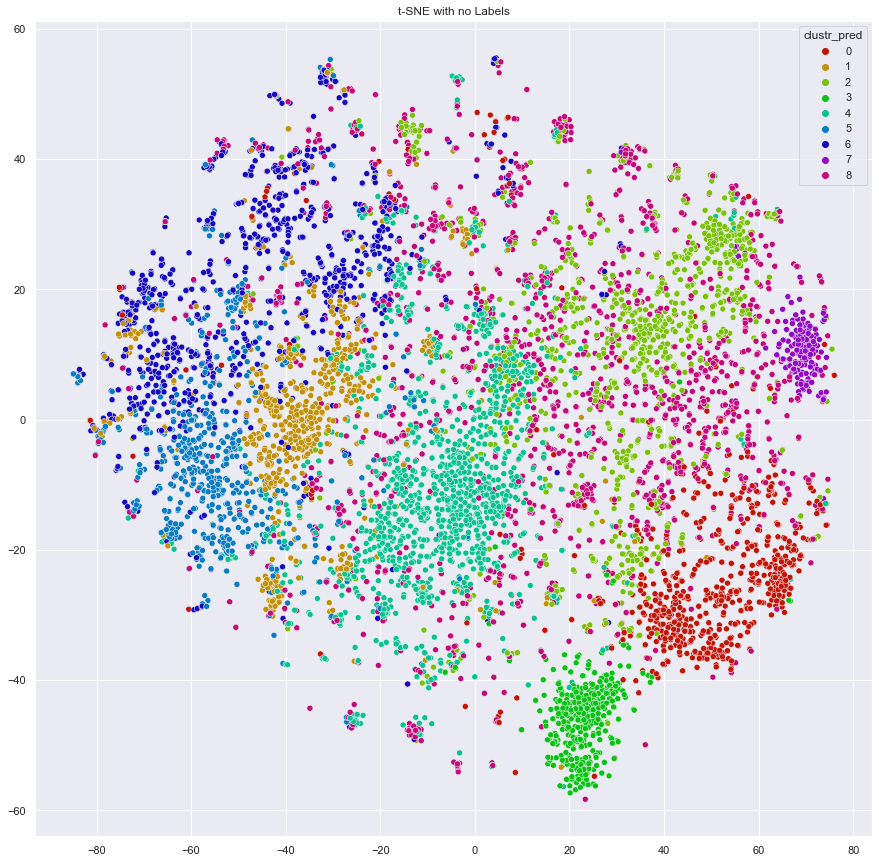

In [63]:
from matplotlib import pyplot as plt
import seaborn as sns

# sns settings
sns.set(rc={'figure.figsize':(15,15)})

# colors
palette = sns.hls_palette(k, l=.4, s=.9) # k=9, 9 clusters here

# plot
sns.scatterplot(X_embedded[:,0], X_embedded[:,1], hue = articles_df['clustr_pred'], palette=palette)
plt.title('t-SNE with no Labels')
plt.savefig("t-sne_covid19.png")
plt.show()

1. The labeled plot gives better insight into how the papers are grouped. 
2. Interestingly, both k-means and t-SNE can find independent clusters even though they were run independently.
3. This shows that structure within the literature can be observed and measured to some extent.
4. Now there are other cases where the colored labels are spread out on the plot. 
5. This is a result of t-SNE and k-means finding different connections in the higher dimensional data. 
6. The topics of these papers often intersect so it was hard to cleanly separate them.

# Topic Modeling on Each Cluster

(a). Let us find the most significant/important words in each cluster <br>
(b). K-means clustered articles but did not find labels of each cluster <br>

In LDA:
1. Each document can be described by a distribution of topics 
2. Each topic can be described by a distribution of words.

In [65]:
from sklearn.feature_extraction.text import CountVectorizer

In [70]:
from sklearn.feature_extraction.text import CountVectorizer

document = ["One Geek helps Two Geeks",
            "Two Geeks help Four Geeks",
            "Each Geek helps many other Geeks at GeeksforGeeks"]

# Create a Vectorizer Object
vectorizer = CountVectorizer()

vectorizer.fit(document)

# Printing the identified Unique words along with their indices
print("Vocabulary: ", vectorizer.vocabulary_)  # all unique words are arranged in alphaetical order a-z
#'at':0 means at is the 1st column of in vector.toarray()

# Encode the Document
vector = vectorizer.transform(document)

# Summarizing the Encoded Texts
print("Encoded Document is:")
print(vector.toarray())

Vocabulary:  {'one': 9, 'geek': 3, 'helps': 7, 'two': 11, 'geeks': 4, 'help': 6, 'four': 2, 'each': 1, 'many': 8, 'other': 10, 'at': 0, 'geeksforgeeks': 5}
Encoded Document is:
[[0 0 0 1 1 0 0 1 0 1 0 1]
 [0 0 1 0 2 0 1 0 0 0 0 1]
 [1 1 0 1 1 1 0 1 1 0 1 0]]


In [71]:
vectorizers = []
    
for i in range(0, k): # k = 9 clusters
    # Creating a vectorizer
    vectorizers.append(CountVectorizer(min_df=5, max_df=0.9, 
                                       stop_words='english', 
                                       lowercase=True, 
                                       token_pattern='[a-zA-Z\-][a-zA-Z\-]{2,}'))
vectorizers # 9 countvectorizers for each cluster of research articles

[CountVectorizer(max_df=0.9, min_df=5, stop_words='english',
                 token_pattern='[a-zA-Z\\-][a-zA-Z\\-]{2,}'),
 CountVectorizer(max_df=0.9, min_df=5, stop_words='english',
                 token_pattern='[a-zA-Z\\-][a-zA-Z\\-]{2,}'),
 CountVectorizer(max_df=0.9, min_df=5, stop_words='english',
                 token_pattern='[a-zA-Z\\-][a-zA-Z\\-]{2,}'),
 CountVectorizer(max_df=0.9, min_df=5, stop_words='english',
                 token_pattern='[a-zA-Z\\-][a-zA-Z\\-]{2,}'),
 CountVectorizer(max_df=0.9, min_df=5, stop_words='english',
                 token_pattern='[a-zA-Z\\-][a-zA-Z\\-]{2,}'),
 CountVectorizer(max_df=0.9, min_df=5, stop_words='english',
                 token_pattern='[a-zA-Z\\-][a-zA-Z\\-]{2,}'),
 CountVectorizer(max_df=0.9, min_df=5, stop_words='english',
                 token_pattern='[a-zA-Z\\-][a-zA-Z\\-]{2,}'),
 CountVectorizer(max_df=0.9, min_df=5, stop_words='english',
                 token_pattern='[a-zA-Z\\-][a-zA-Z\\-]{2,}'),
 CountVectorizer

In [72]:
vectorizeData = []

for currentCluster, cvec in enumerate(vectorizers):
    textDataInCurrCluster = articles_df.loc[articles_df['clustr_pred'] == currentCluster, 'cleaned_body_text']
    vectorizedClusData = cvec.fit_transform(textDataInCurrCluster)
    vectorizeData.append(vectorizedClusData)

In [73]:
len(vectorizeData)

9

In [75]:
# LDA
# Number of topics per cluster
NUM_TOPICS_PER_CLUSTER = 20
lda_models = []

from sklearn.decomposition import LatentDirichletAllocation
for i in range(0, k): # k = 9 clusters
    # Latent Dirichlet Allocation Model
    lda = LatentDirichletAllocation(
                                    n_components = NUM_TOPICS_PER_CLUSTER, 
                                    max_iter = 10, 
                                    learning_method = 'online',
                                    verbose = False, 
                                    random_state = 42)
    lda_models.append(lda)
    
lda_models[0]

LatentDirichletAllocation(learning_method='online', n_components=20,
                          random_state=42, verbose=False)

In [76]:
clusteredDataLDA = []
for i in range(0, k): # k = 9 clusters
    print('Current Cluster: ', str(i))
    clusteredDataLDA.append(lda_models[i].fit_transform(vectorizeData[i]))

Current Cluster:  0
Current Cluster:  1
Current Cluster:  2
Current Cluster:  3
Current Cluster:  4
Current Cluster:  5
Current Cluster:  6
Current Cluster:  7
Current Cluster:  8


In [79]:
# Functions for printing keywords for each topic
def selected_topics(model, vectorizer, top_n=3):
    current_words = []
    keywords = []
    
    for idx, topic in enumerate(model.components_):
        words = [(vectorizer.get_feature_names()[i], topic[i]) for i in topic.argsort()[:-top_n - 1:-1]]
        for word in words:
            if word[0] not in current_words:
                keywords.append(word)
                current_words.append(word[0])
                
    keywords.sort(key = lambda x: x[1])  
    keywords.reverse()
    return_values = []
    for i in keywords:
        return_values.append(i[0])
    return return_values

In [ ]:
all_keywords = []
for current_vectorizer, lda in enumerate(lda_models):
    print("Current Cluster: " + str(current_vectorizer))

    if vectorized_data[current_vectorizer] != None:
        all_keywords.append(selected_topics(lda, vectorizers[current_vectorizer]))